In [ ]:
import MDAnalysis as mda
from MDAnalysis.topology.tables import vdwradii
import prolif as plf
from prolif.plotting.network import LigNetwork
import itertools
from functools import lru_cache
from collections import defaultdict
import json
import re
from html import escape
import warnings
import pathlib
import requests

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.patches import Patch, Rectangle
import seaborn as sns
from IPython.display import IFrame, HTML
from sklearn.cluster import KMeans
from scipy.cluster.vq import vq
import networkx as nx
from pyvis.network import Network
from rdkit import Chem
from rdkit.Chem import DataStructs

/Users/bdahmer/miniconda3/envs/prolif/lib/python3.14/site-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


## 1) Molecular Dynamics trajectory of a protein–ligand complex

This Jupyter notebook uses, as an example, a MD trajectory of mTOR in complex with Resveratrol.
There are 300 ns of simulation time, with 0.1 ns between each frame. The trajectory is already centered and fitted, so no need to postprocess it.

/var/folders/ll/8nkfxshj0579_n26fqpcpvx40000gn/T/ipykernel_55871/4204645996.py:6: DeprecationWarning: `guess_atom_element` is deprecated!
`guess_atom_element` will be removed in release 3.0.0.
MDAnalysis.topology.guessers is deprecated in favour of the new Guessers API. See MDAnalysis.guesser.default_guesser for more details.
  elements = [mda.topology.guessers.guess_atom_element(n) for n in u.atoms.names]


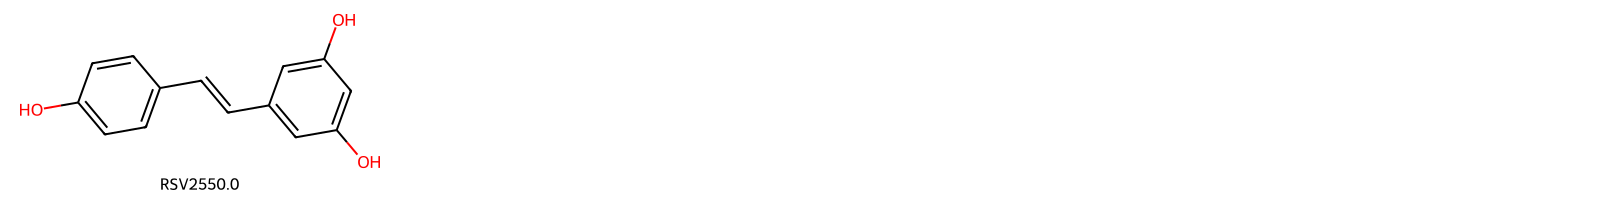

In [ ]:
#load topology and trajectory files with MDAnalysis
u = mda.Universe(
    "mtor-rsv36.gro",
    "md-rsv36-fitted.xtc"
)
elements = [mda.topology.guessers.guess_atom_element(n) for n in u.atoms.names]
u.add_TopologyAttr("elements", elements)
# create selections for the ligand and protein
lig = u.atoms.select_atoms("resname RSV")

# create a molecule from the MDAnalysis selection
'''
This next step is crucial if you’re loading a structure from a file that doesn’t explicitely contain bond orders
and formal charges, such as a PDB file or most MD trajectory files.
MDAnalysis will infer those from the atoms connectivity,
which requires all atoms including hydrogens to be present in the input file.
'''
lig.guess_bonds()
ligand_mol = plf.Molecule.from_mda(lig)

prot = u.atoms.select_atoms("protein and byres around 20.0 resname RSV")
# same for protein if necessary
prot.guess_bonds()
protein_mol = plf.Molecule.from_mda(prot)

lig, prot

# display ligand
plf.display_residues(ligand_mol, size=(400, 200))

Note that the selection argument "protein and byres around 20.0 resname RSV" will only select residues around 20 Å of the ligand on the first frame. In case your ligand (or protein) moves significantly during the simulation and moves outside of this 20 Å sphere, it may be more relevant to perform such a selection multiple times during the simulation to encompass all the relevant residues across the entire trajectory.

To this effect, you can use prolif.utils.select_over_trajectory:


In [ ]:
prot = plf.select_over_trajectory(
    u,
    u.trajectory[::10], #updates selection every 10 frames
    "protein and byres around 6.0 group ligand",
    ligand=lig,
)

ProLIF considers a variety of possible interaction types, which the user can decide to include or exclude from analysis. The next cell lists the available interaction fingerprints. To include/exclude specific interaction types, modify the list. Alternatively, fp = plf.Fingerprint() is enough to use the default interactions.

In [ ]:
plf.Fingerprint.list_available()

['Anionic',
 'CationPi',
 'Cationic',
 'EdgeToFace',
 'FaceToFace',
 'HBAcceptor',
 'HBDonor',
 'Hydrophobic',
 'MetalAcceptor',
 'MetalDonor',
 'PiCation',
 'PiStacking',
 'VdWContact',
 'XBAcceptor',
 'XBDonor']

In [ ]:
#use alternative fingerprints
fp = plf.Fingerprint(['Hydrophobic', 'HBDonor', 'HBAcceptor', 'Anionic', 'Cationic', 'CationPi', 'PiCation',
                          'PiStacking', 'MetalAcceptor'])

#run through frames with a time step of 2
fp.run(u.trajectory[::2], lig, prot)
# convert the results to a pandas DataFrame, by saving the fingerprint object with fp.to_pickle
# and reload it later with Fingerprint.from_pickle:
df = fp.to_dataframe()
df.to_pickle("rsv36_ifp_df.pkl")
# show only the 5 first frames
df = df.reindex(sorted(df.columns), axis=1)
# show only the 5 first frames
df.head(5)
# we can also export the dataframe as a .CSV file
df.to_csv('rsv36_output.csv', sep='\t')

  0%|          | 0/1501 [00:00<?, ?it/s]

## 2) Data Analysis with pandas

Exporting the fingerprint to a DataFrame allows to easily address common questions like which residues are involved in a specific type of interaction, which interactions does a specific residue do, which are the most frequent types of interactions, or which are the residues most frequently interacting with the ligand.

In [ ]:
df = (pd.read_pickle("rsv36_ifp_df.pkl")
        .astype(np.uint8))

In [ ]:
# show only one protein residue (ASP2195.0)
df.xs("ASP2195.0", level="protein", axis=1).head(5)

ligand        RSV2550.0        
interaction Hydrophobic HBDonor
Frame                          
0                     0       1
2                     0       1
4                     0       1
6                     0       1
8                     0       1

In [ ]:
# show only an interaction type (PiStacking)
df.xs("PiStacking", level="interaction", axis=1).head(5)

ligand  RSV2550.0          
protein TYR2225.0 TRP2239.0
Frame                      
0               1         0
2               0         1
4               1         0
6               0         0
8               0         0

In [ ]:
# percentage of the trajectory where each interaction is present
(df.mean().sort_values(ascending=False).to_frame(name="%").T * 100)

ligand        RSV2550.0                                                 \
protein       TRP2239.0   ILE2356.0   TYR2225.0   ASP2357.0  ASP2195.0   
interaction Hydrophobic Hydrophobic Hydrophobic Hydrophobic    HBDonor   
%             96.935376   96.069287   90.806129   89.473684  79.746835   

ligand                                                                 ...  \
protein      VAL2240.0   MET2345.0   ILE2237.0   PHE2358.0             ...   
interaction HBAcceptor Hydrophobic Hydrophobic Hydrophobic HBAcceptor  ...   
%            76.682212   59.493671   56.628914   44.503664  36.175883  ...   

ligand                                                                        \
protein       GLN2167.0  ASP2357.0   ILE2163.0 ASP2357.0 GLU2190.0 GLN2167.0   
interaction Hydrophobic HBAcceptor Hydrophobic   HBDonor   HBDonor   HBDonor   
%              4.530313   4.530313    2.798135  2.531646  1.598934   1.46569   

ligand                                                   
protein     VAL2240.0 TYR2225.0   ASP2195.0   LEU2354.0  
interaction   HBDonor   HBDonor Hydrophobic Hydrophobic  
%              0.5996  0.333111    0.266489    0.133245  

[1 rows x 26 columns]

Hydrophobic interactions with Trp2239, Ile2356, Tyr2225, Asp2357 are present in 97%, 96%, 90%, and 89% of frames.
The ligand is donating a H-bond to Asp2195 in 79% of frames.

In [ ]:
# same but we regroup all interaction types per residue
(
    df.T.groupby(level=["ligand", "protein"])
    .sum()
    .T.astype(bool)
    .mean()
    .sort_values(ascending=False)
    .to_frame(name="%")
    .T
    * 100
)

ligand   RSV2550.0                                                         \
protein  TRP2239.0  ILE2356.0  TYR2225.0  ASP2357.0  VAL2240.0  ASP2195.0   
%        97.068621  96.069287  91.072618  90.339773  81.212525  79.746835   

ligand                                                                    \
protein  MET2345.0  PHE2358.0  ILE2237.0  LYS2187.0  LEU2185.0 GLN2167.0   
%        59.493671  58.427715  56.628914  42.504997  26.982012  5.996003   

ligand                                 
protein ILE2163.0 GLU2190.0 LEU2354.0  
%        2.798135  1.598934  0.133245

In [ ]:
# occurence percentage of each TYPE of interaction along the simulation
(
    df.T.groupby(level=["interaction"])
    .sum()
    .T.astype(bool)
    .mean()
    .sort_values(ascending=False)
    .to_frame(name="%")
    .T
    * 100
)

interaction,Hydrophobic,HBAcceptor,HBDonor,PiStacking
%,100.0,86.608927,82.411726,35.109927


Hydrophobic interactions are present in 100% of frames; the ligand acts as an H-bond acceptor and donor in 83.81% and 73.28% of frames, and so on.

In [ ]:
# percentage of the trajectory where PiStacking interactions are present, by residue
(
    df.xs("PiStacking", level="interaction", axis=1)
    .mean()
    .sort_values(ascending=False)
    .to_frame(name="%")
    .T
    * 100
)

ligand   RSV2550.0           
protein  TYR2225.0  TRP2239.0
%        21.252498  16.588941

The ligand forms pi-stacking interactions with Try2225 and Trp2239 in 21.25% and 16.59% of frames.

In [ ]:
# share, by residue, of pi-stacking interactions
pi = (df.xs("PiStacking", level="interaction", axis=1)
       .sum())

# share, by residue, of HBDonor interactions
hbd = (df.xs("HBDonor", level="interaction", axis=1)
       .sum())

# share, by residue, of HBAcceptor interactions
hba = (df.xs("HBAcceptor", level="interaction", axis=1)
       .sum())

# share, by residue, of Hydrophobic interactions
hyd = (df.xs("Hydrophobic", level="interaction", axis=1)
       .sum())

print("PiStacking","\n",(100 * pi / pi.sum()).sort_values(ascending=False),"\n",
      "HBDonor","\n",(100 * hbd / hbd.sum()).sort_values(ascending=False),"\n",
      "HBAcceptor","\n",(100 * hba / hba.sum()).sort_values(ascending=False),"\n",
      "Hydrophobic","\n",(100 * hyd / hyd.sum()).sort_values(ascending=False),"\n")

PiStacking 
 ligand     protein  
RSV2550.0  TYR2225.0    56.161972
           TRP2239.0    43.838028
dtype: float64 
 HBDonor 
 ligand     protein  
RSV2550.0  ASP2195.0    92.432432
           ASP2357.0     2.934363
           GLU2190.0     1.853282
           GLN2167.0     1.698842
           VAL2240.0     0.694981
           TYR2225.0     0.386100
dtype: float64 
 HBAcceptor 
 ligand     protein  
RSV2550.0  VAL2240.0    57.435130
           PHE2358.0    27.095808
           LYS2187.0    12.075848
           ASP2357.0     3.393214
dtype: float64 
 Hydrophobic 
 ligand     protein  
RSV2550.0  TRP2239.0    15.307733
           ILE2356.0    15.170963
           TYR2225.0    14.339821
           ASP2357.0    14.129406
           MET2345.0     9.395055
           ILE2237.0     8.942662
           PHE2358.0     7.027880
           LYS2187.0     5.449763
           VAL2240.0     4.755392
           LEU2185.0     4.260915
           GLN2167.0     0.715413
           ILE2163.0     0.441873

Tyr2225 makes 56% of all the "PiStacking" interactions; Trp2239 makes the remaining 44%.
Asp2195 makes 92.43% of all the "HBDonor" interactions.

### IMPORTANT:
"Interactions" or fingerprints, for hydrogen bonding especially, refer to the role taken by the **ligand**; as such, Asp2195 acts as a **H-bond acceptor**.

In [ ]:
# percentage of frames in which ligand interacts with protein residue
(
    df.T.groupby(level=["ligand", "protein"])
    .sum()
    .T.astype(bool)
    .mean()
    .sort_values(ascending=False)
    .to_frame(name="%")
    .T
    * 100
)

ligand   RSV2550.0                                                         \
protein  TRP2239.0  ILE2356.0  TYR2225.0  ASP2357.0  VAL2240.0  ASP2195.0   
%        97.068621  96.069287  91.072618  90.339773  81.212525  79.746835   

ligand                                                                    \
protein  MET2345.0  PHE2358.0  ILE2237.0  LYS2187.0  LEU2185.0 GLN2167.0   
%        59.493671  58.427715  56.628914  42.504997  26.982012  5.996003   

ligand                                 
protein ILE2163.0 GLU2190.0 LEU2354.0  
%        2.798135  1.598934  0.133245

In [ ]:
# 10 residues most frequently interacting with the ligand
(
    df.T.groupby(level=["ligand", "protein"])
    .sum()
    .T.astype(bool)
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("%")
    .T
    * 100
)

ligand   RSV2550.0                                                         \
protein  TRP2239.0  ILE2356.0  TYR2225.0  ASP2357.0  VAL2240.0  ASP2195.0   
%        97.068621  96.069287  91.072618  90.339773  81.212525  79.746835   

ligand                                               
protein  MET2345.0  PHE2358.0  ILE2237.0  LYS2187.0  
%        59.493671  58.427715  56.628914  42.504997

The fingerprint can also be converted to an RDKit bitvector to make use of the similarity/distance metric functions implemented. This allows to investigate the presence of different binding modes in the simulation.

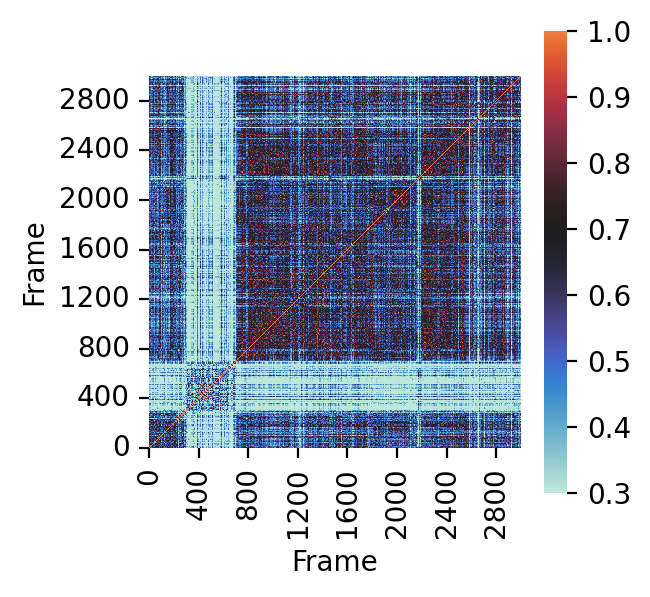

In [ ]:
# compute tanimoto similarity matrix
bvs = plf.to_bitvectors(df)
mat = []
for bv in bvs:
    mat.append(DataStructs.BulkTanimotoSimilarity(bv, bvs))
mat = pd.DataFrame(mat, index=df.index, columns=df.index)

# display heatmap
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
colormap = sns.diverging_palette(300, 145, s=90, l=80, sep=30, center="dark", as_cmap=True)

sns.heatmap(
    mat, ax=ax, square=True,
    cmap="icefire",
    vmin=.3, vmax=1, center=.7,
    xticklabels=200, yticklabels=200,
)

ax.invert_yaxis()
fig.patch.set_facecolor('white')

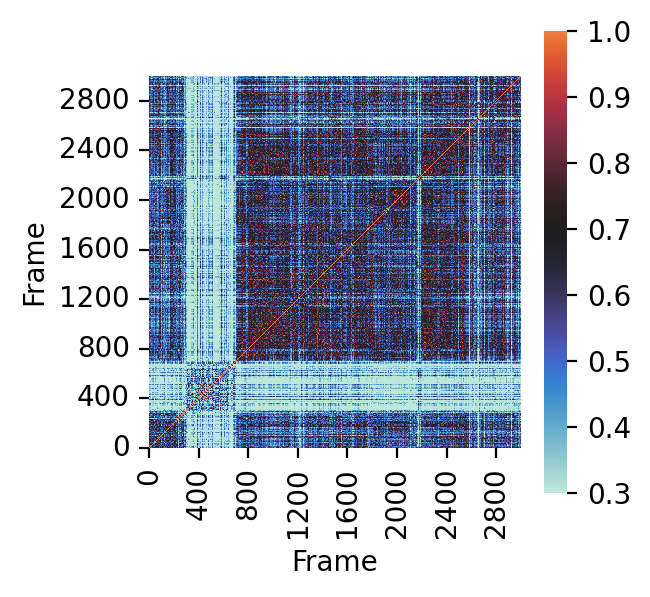

In [ ]:
# Tanimoto similarity matrix
bitvectors = fp.to_bitvectors()
similarity_matrix = []
for bv in bitvectors:
    similarity_matrix.append(DataStructs.BulkTanimotoSimilarity(bv, bitvectors))
similarity_matrix = pd.DataFrame(similarity_matrix, index=df.index, columns=df.index)

# display heatmap
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
#colormap = sns.diverging_palette(300, 145, s=90, l=80, sep=30, center="dark", as_cmap=True)

sns.heatmap(
    similarity_matrix, ax=ax, square=True,
    cmap="icefire",
    vmin=.3, vmax=1, center=.7,
    xticklabels=200, yticklabels=200,
)

ax.invert_yaxis()
plt.yticks(rotation="horizontal")
fig.patch.set_facecolor("white")

In [ ]:
fig.savefig("rsv36_similarity_matrix.png", bbox_inches="tight", dpi=300)

In [ ]:
# we can also regroup frames of the same cluster with kmeans clustering
# KMeans clustering

def bv_to_np(bv):
    """convert rdkit bitvector to numpy array"""
    arr = np.zeros((0,))
    DataStructs.ConvertToNumpyArray(bv, arr)
    return arr

fps = np.array([bv_to_np(bv) for bv in bvs])
kmean = KMeans(n_clusters=2, random_state=0)
clusters = kmean.fit_predict(fps)

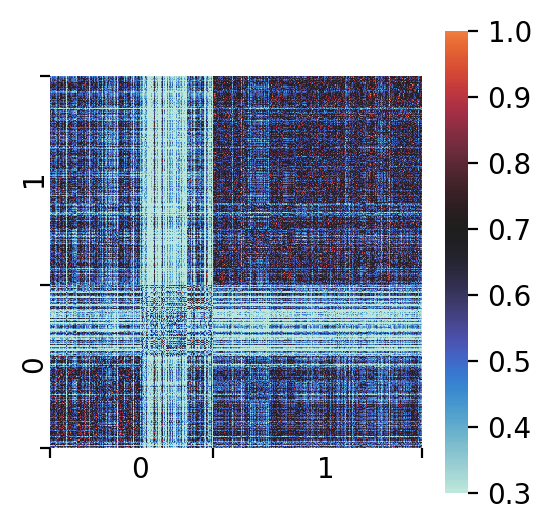

In [ ]:
# display heatmap sorted by cluster
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)
sns.heatmap(
    # matrix sorted by cluster
    (mat
     .set_axis(clusters, axis=0)
     .set_axis(clusters, axis=1)
     .sort_index(axis=0)
     .sort_index(axis=1)
    ),
    ax=ax, square=True,
    cmap="icefire",
    vmin=.3, vmax=1, center=.7,
    xticklabels=75,
    yticklabels=0,
)

# show tick on heatmap's y-axis when new cluster
sc = np.sort(clusters)
# find index where a new cluster is assigned
s = np.argwhere(sc[1:] - sc[:-1]) + 1
s = s.flatten().tolist()
s = [0] + s + [sc.size]
# set on y axis
ax.set_yticks(s)
ax.set_xticks(s)
ax.invert_yaxis()
# ax.yaxis.labelpad = 8
for c, (i1, i2) in enumerate(zip(s[:-1], s[1:])):
    ax.text(-120, (i1 + i2) / 2, c, rotation=90)
    ax.text((i1 + i2) / 2, -120, c, rotation=0)
fig.patch.set_facecolor('white')

In [ ]:
fig.savefig("rsv36_similarity_matrix_clustered.png", bbox_inches="tight", dpi=300)

In [ ]:
# get closest frame to each cluster center
closest, dists = vq(kmean.cluster_centers_, fps)
data = df.iloc[closest].copy()
# only show columns with differences between clusters
data.loc[:, data.nunique() > 1]

ligand        RSV2550.0                       
protein       ILE2237.0   PHE2358.0           
interaction Hydrophobic Hydrophobic HBAcceptor
Frame                                         
248                   0           0          0
754                   1           1          1

We've divided the Tanimoto similarity matrix into two clusters. These clusters may reveal changes in interactions between the ligand and the protein. Indeed, these are indicated by Hydrophobic interaction with Ile2237 and both Hydrophobic and HBAcceptor interactions with Phe2358, which are absent in the first cluster.

## Visualization

There are a few different options builtin when it comes to visualisation of interaction fingerprints throughout the MD trajectory.

We can start by plotting the interactions over time:

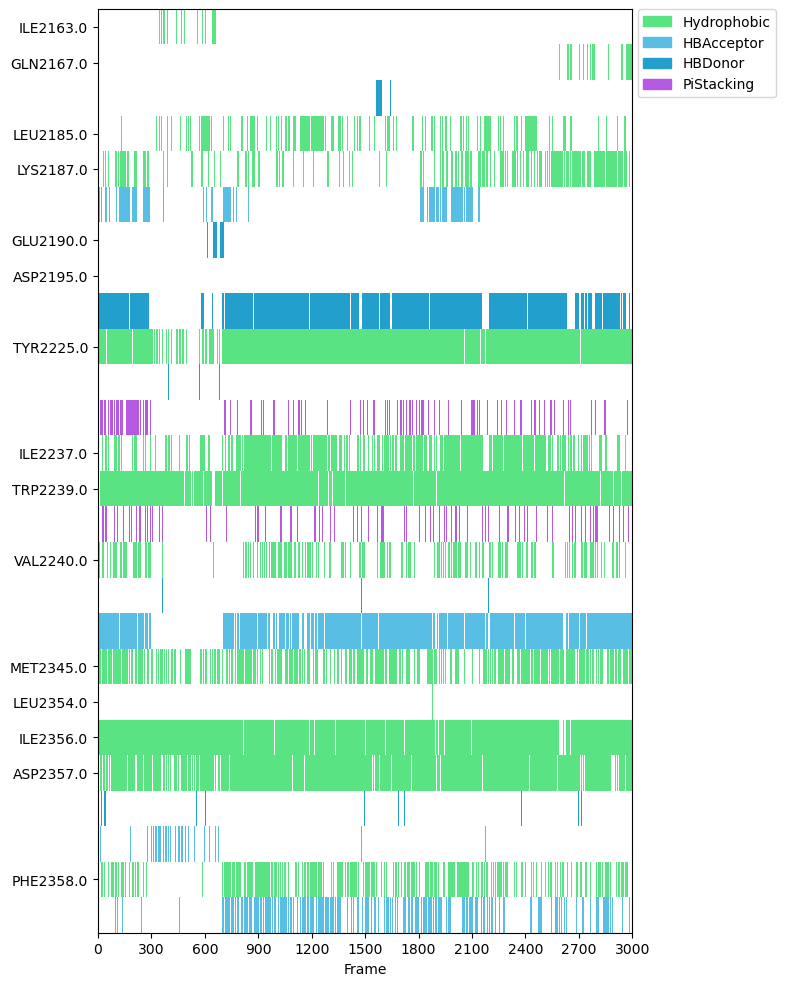

In [ ]:
from prolif.plotting.barcode import Barcode
Barcode.from_fingerprint(fp).display(figsize=(8, 10)).figure.savefig('rsv36_barcode.png', dpi=300)

We can easily visualize the off-diagonal region in the Tanimoto similarity matrix around frames 400–800 in the gaps of the interaction timeseries above.

We can also display the interactions in a 2D interactive diagram. You can:
zoom and pan,
move residues around,
click on the legend to display or hide types of residues or interactions,
hover (or click) an interaction line to display the distance.

The threshold parameter in the command below controls the minimum frequency required for an interaction to be displayed (default 0.3, meaning that interactions occuring in less than 30% of frames will be hidden). The width of the dashed line represents the frequency of corresponding interaction.

In [ ]:
view = fp.plot_lignetwork(ligand_mol, kind="aggregate", threshold = 0.3)
view

In [ ]:
view.save_png()

<IPython.core.display.Javascript object>

Up to now we've only been using the default fingerprint generator, but you can optionally enable the count
parameter to enumerate all occurences of an interaction (the default fingerprint generator will stop at the first occurence),
and then display all of them by specifying display_all=True:

In [ ]:
fp_count = plf.Fingerprint(count=True)
fp_count.run(u.trajectory[0:1], lig, prot)
view = fp_count.plot_lignetwork(ligand_mol, display_all=False, threshold=0.3)
view

  0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
view.save_png()

<IPython.core.display.Javascript object>

We can also visualize this information in 3D:

In [ ]:
frame = 0
# seek specific frame
u.trajectory[frame]
ligand_mol = plf.Molecule.from_mda(lig)
protein_mol = plf.Molecule.from_mda(prot)
# display
view = fp_count.plot_3d(ligand_mol, protein_mol, frame=frame, display_all=False)
view

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

As in the lignetwork plot, you can hover atoms and interactions to display more information.

The advantage of using a count fingerprint in that case is that it will automatically select
the interaction occurence with the shortest distance for a more intuitive visualization.

Once you're satisfied with the orientation, you can export the view as a PNG image with:

In [ ]:
view.save_png()

<IPython.core.display.Javascript object>

You can also compare two different frames on the same view, and the protein residues that have different interactions
in the other frame or are missing will be highlighted in magenta:

In [ ]:
from prolif.plotting.complex3d import Complex3D

'''We can compare the frames obtained with the Tanimoto similarity analysis'''
frame = 248
u.trajectory[frame]
ligand_mol = plf.Molecule.from_mda(lig)
protein_mol = plf.Molecule.from_mda(prot)
comp3D = Complex3D.from_fingerprint(fp, ligand_mol, protein_mol, frame=frame)

frame = 754
u.trajectory[frame]
ligand_mol = plf.Molecule.from_mda(lig)
protein_mol = plf.Molecule.from_mda(prot)
other_comp3D = Complex3D.from_fingerprint(fp, ligand_mol, protein_mol, frame=frame)

view = comp3D.compare(other_comp3D)
view

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
view.save_png()

<IPython.core.display.Javascript object>